# Iris 数据分析：从原始数据到可建模特征

本实验对应知识库的“数据与特征”章节。目标不是立即训练分类器，而是先完成一条可检查的数据理解链：

1. 定义样本、特征与标签；
2. 检查缺失、重复、类型和类别平衡；
3. 比较特征分布与尺度；
4. 分析特征之间的相关性和类别分离；
5. 构造一个候选特征，并说明它仍需后续模型验证。

数据来源：scikit-learn 内置 Iris 数据集，150 个样本、4 个连续特征、3 个类别。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "实验").exists():
    for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
        if (candidate / "实验").exists() and (candidate / "知识库").exists():
            PROJECT_ROOT = candidate
            break

OUTPUT_DIR = PROJECT_ROOT / "实验/outputs/iris_data_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

FEATURES = ["花萼长度", "花萼宽度", "花瓣长度", "花瓣宽度"]
PALETTE = {"setosa": "#3B82F6", "versicolor": "#F59E0B", "virginica": "#10B981"}

def savefig(name):
    path = OUTPUT_DIR / name
    plt.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    print(f"已保存：{path.relative_to(PROJECT_ROOT)}")
    return path

## 1. 定义数据：一行、一列和一个标签分别是什么

先把数据表翻译成机器学习对象。每一行是一朵花，四个测量值组成输入向量 $\mathbf{x}_i$，品种是分类标签 $y_i$。

In [2]:
bundle = load_iris(as_frame=True)
X = bundle.data.copy()
X.columns = FEATURES
y = bundle.target.map(dict(enumerate(bundle.target_names))).rename("品种")
df = pd.concat([X, y], axis=1)

print(f"样本数 n = {len(df)}")
print(f"特征数 d = {X.shape[1]}")
display(df.head())
display(pd.DataFrame({
    "数据类型": df.dtypes.astype(str),
    "缺失数": df.isna().sum(),
    "唯一值数": df.nunique(),
}))

样本数 n = 150
特征数 d = 4


,花萼长度,花萼宽度,花瓣长度,花瓣宽度,品种
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,数据类型,缺失数,唯一值数
花萼长度,float64,0,35
花萼宽度,float64,0,23
花瓣长度,float64,0,43
花瓣宽度,float64,0,22
品种,str,0,3


**观察**

- 输入 $X$ 是 $150	imes4$ 的数值矩阵，标签 $y$ 有三个取值。
- 四个输入都是连续测量值，没有需要编码的类别型输入。
- 这一定义同时支持后续三分类；暂时忽略 $y$ 时，也能用于 PCA 和 K-Means。

## 2. 数据诊断：缺失、重复与类别平衡

“没有报错”不等于数据质量已经确认。先对最基本的质量维度做显式检查，再决定是否处理。

,检查项,结果,处理判断
0,缺失单元格,0,无需填补
1,完全相同记录,1,标记但不盲目删除
2,数值特征,4,可直接分析
3,类别数,3,检查类别数量


,样本数
品种,
setosa,50
versicolor,50
virginica,50


findfont: Failed to find font weight bold, now using 600.


已保存：实验/outputs/iris_data_analysis/01_data_overview.png


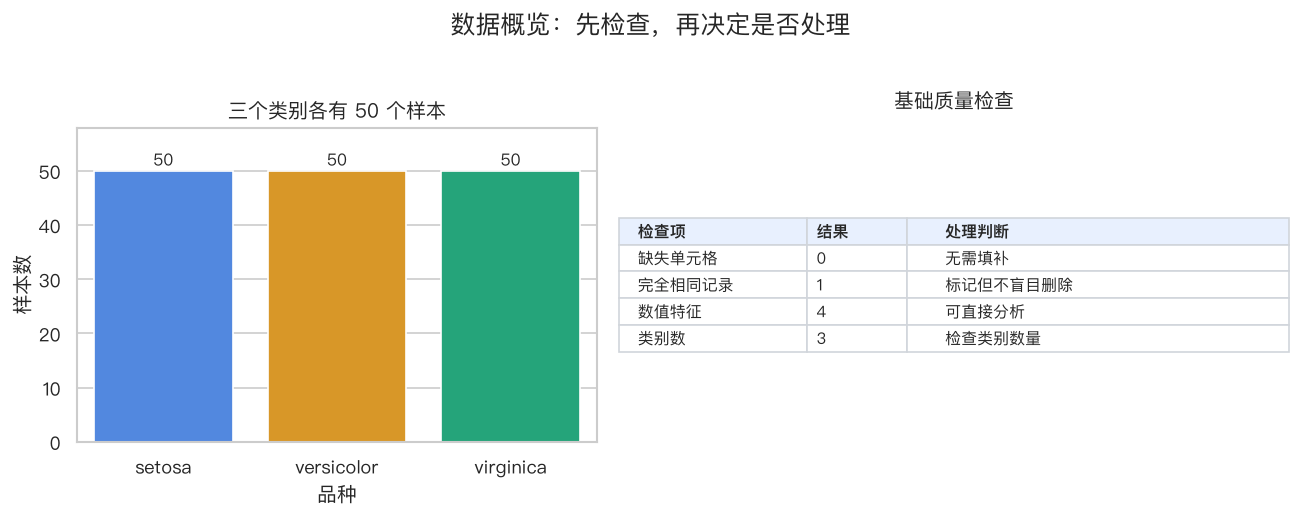

In [3]:
quality = pd.DataFrame({
    "检查项": ["缺失单元格", "完全相同记录", "数值特征", "类别数"],
    "结果": [int(df.isna().sum().sum()), int(df.duplicated().sum()), X.shape[1], y.nunique()],
    "处理判断": ["无需填补", "标记但不盲目删除", "可直接分析", "检查类别数量"],
})
class_counts = y.value_counts().reindex(bundle.target_names)
display(quality)
display(class_counts.rename("样本数").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.05, 1.35]})
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index,
            palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("三个类别各有 50 个样本")
axes[0].set_xlabel("品种")
axes[0].set_ylabel("样本数")
axes[0].set_ylim(0, 58)
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 1, str(v), ha="center", fontsize=10)

axes[1].axis("off")
table = axes[1].table(cellText=quality.values, colLabels=quality.columns,
                      cellLoc="left", colLoc="left", loc="center",
                      colWidths=[0.28, 0.15, 0.57])
table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1, 1.65)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#D1D5DB")
    if row == 0:
        cell.set_facecolor("#E8F0FE")
        cell.set_text_props(weight="bold")
axes[1].set_title("基础质量检查", pad=12)
plt.suptitle("数据概览：先检查，再决定是否处理", fontsize=15, y=1.02)
plt.tight_layout()
savefig("01_data_overview.png")
plt.show()

**观察与判断**

- 没有缺失值，因此本实验不需要填补。
- 三类完全均衡，当前不需要重采样或类别权重。
- 有一条数值完全相同的记录，但没有样本主键可证明它是重复采集，所以只记录现象，不机械删除。

这一步体现了预处理的基本原则：处理动作必须由数据问题和任务语义共同决定。

## 3. 单变量分布：每个特征能否区分类别

把四个特征分别按品种画出分布。这里关注的不是图是否好看，而是类别重叠程度：重叠越少，该特征单独提供的分类信息通常越清晰。

已保存：实验/outputs/iris_data_analysis/02_feature_distributions.png


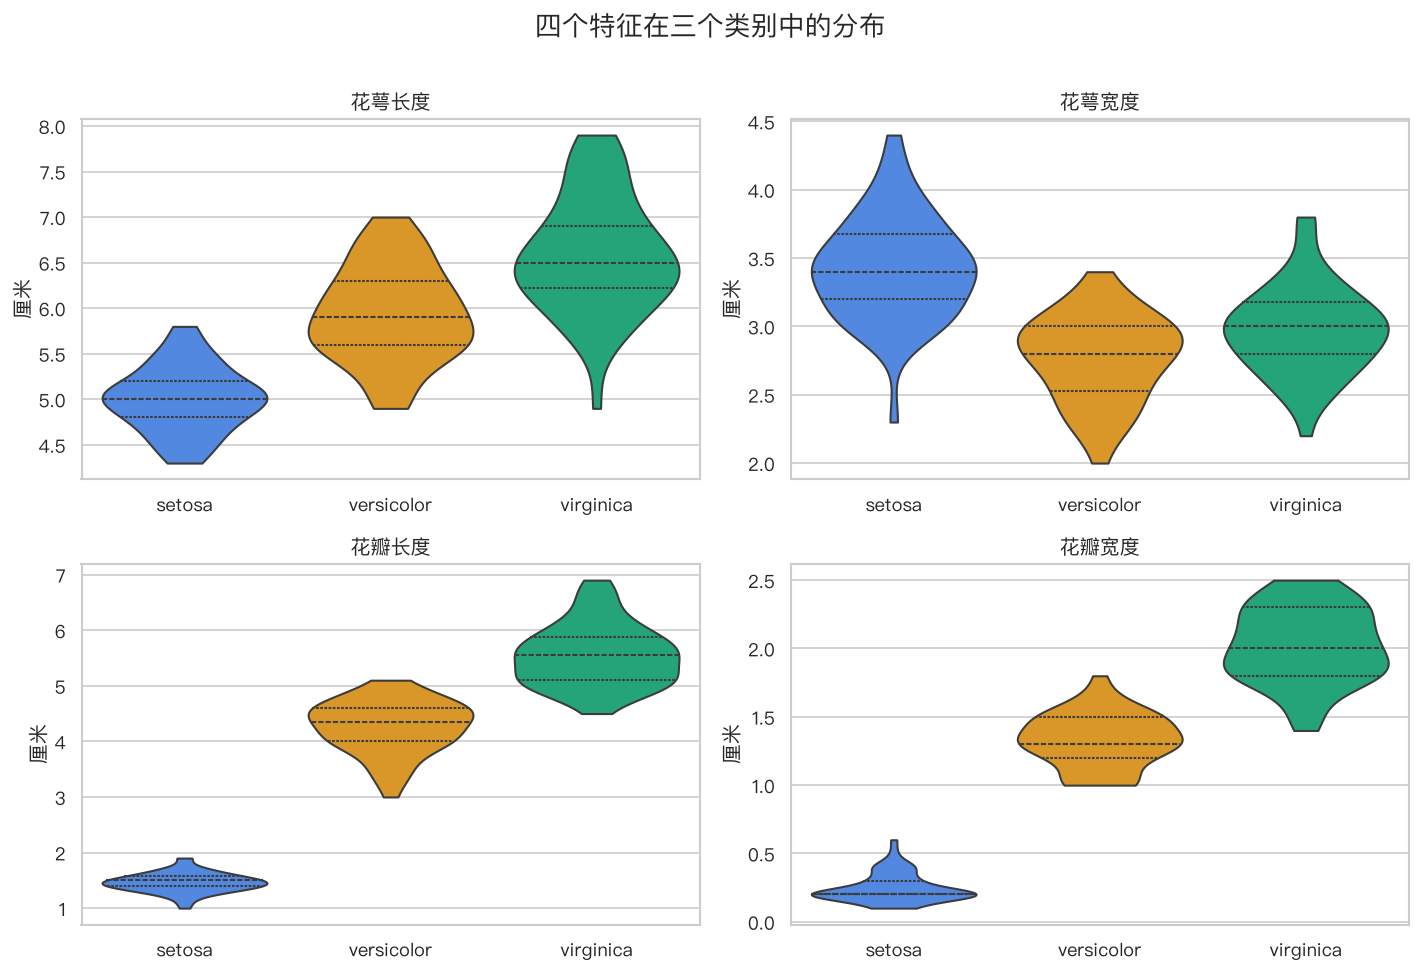

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for ax, feature in zip(axes.flat, FEATURES):
    sns.violinplot(data=df, x="品种", y=feature, hue="品种", palette=PALETTE,
                   inner="quartile", cut=0, legend=False, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("厘米")
plt.suptitle("四个特征在三个类别中的分布", fontsize=16, y=1.01)
plt.tight_layout()
savefig("02_feature_distributions.png")
plt.show()

**观察与结论**

- setosa 的花瓣长度和花瓣宽度与另外两类明显分开。
- versicolor 与 virginica 在花萼特征上重叠较多，在花瓣特征上分离更清楚。
- 因此后续二维决策边界可优先使用花瓣长度和花瓣宽度；这是一种便于解释的视角选择，不等于只用两个特征一定得到最高精度。

## 4. 特征缩放：统一尺度，不改变相对顺序

四个变量都以厘米计量，但数值范围和标准差不同。标准化把每列转换为“距离该列均值多少个标准差”，使距离、梯度和方差方向不再被原始尺度直接主导。

,原始值,均值,总体标准差,手算 z,StandardScaler
花萼长度,5.1,5.843,0.825,-0.901,-0.901
花萼宽度,3.5,3.057,0.434,1.019,1.019
花瓣长度,1.4,3.758,1.759,-1.340,-1.340
花瓣宽度,0.2,1.199,0.760,-1.315,-1.315


已保存：实验/outputs/iris_data_analysis/03_scaling_comparison.png


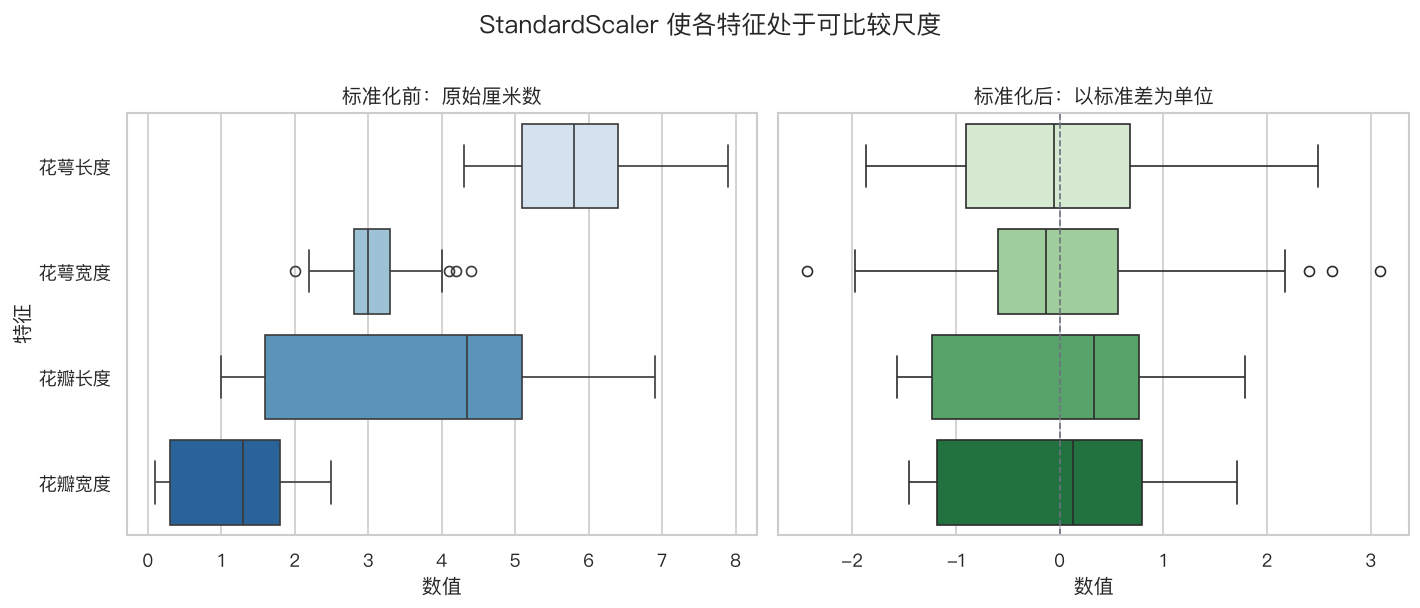

In [5]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=FEATURES)

check = pd.DataFrame({
    "原始值": X.iloc[0],
    "均值": X.mean(),
    "总体标准差": X.std(ddof=0),
    "手算 z": (X.iloc[0] - X.mean()) / X.std(ddof=0),
    "StandardScaler": X_scaled.iloc[0],
})
display(check.round(3))

raw_long = X.melt(var_name="特征", value_name="数值")
scaled_long = X_scaled.melt(var_name="特征", value_name="数值")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.boxplot(data=raw_long, y="特征", x="数值", hue="特征", legend=False,
            palette="Blues", ax=axes[0])
axes[0].set_title("标准化前：原始厘米数")
sns.boxplot(data=scaled_long, y="特征", x="数值", hue="特征", legend=False,
            palette="Greens", ax=axes[1])
axes[1].axvline(0, color="#6B7280", linewidth=1, linestyle="--")
axes[1].set_title("标准化后：以标准差为单位")
plt.suptitle("StandardScaler 使各特征处于可比较尺度", fontsize=15, y=1.01)
plt.tight_layout()
savefig("03_scaling_comparison.png")
plt.show()

**观察与边界**

- 第一条样本的花萼长度标准化结果约为 $-0.901$，手算与 `StandardScaler` 一致。
- 标准化改变数值中心和尺度，但不会改变同一特征内部的样本先后关系。
- 本节为理解变换而在完整 Iris 上展示统计量。正式建模时必须先划分数据，再只在训练集上 `fit` scaler。

## 5. 特征关系：相关性不等于可分性

相关矩阵回答“两个数值特征是否共同变化”；成对散点回答“在这个二维视角中，类别是否容易分开”。两者不是同一个问题。

,花萼长度,花萼宽度,花瓣长度,花瓣宽度
花萼长度,1.000,-0.118,0.872,0.818
花萼宽度,-0.118,1.000,-0.428,-0.366
花瓣长度,0.872,-0.428,1.000,0.963
花瓣宽度,0.818,-0.366,0.963,1.000


已保存：实验/outputs/iris_data_analysis/04_correlation_structure.png


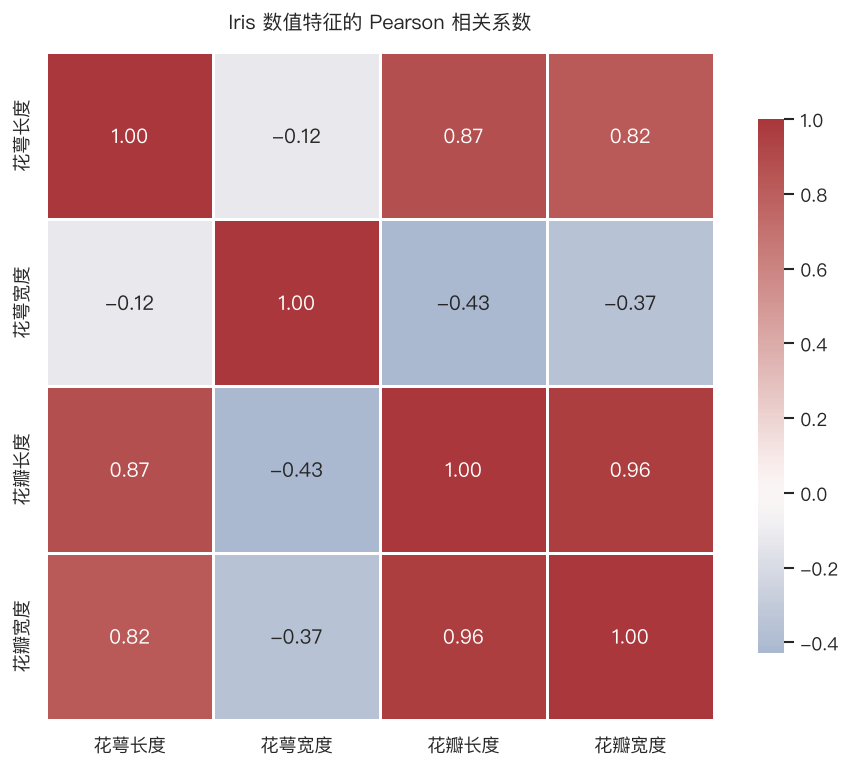

In [6]:
corr = X.corr()
display(corr.round(3))

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            square=True, linewidths=0.7, cbar_kws={"shrink": 0.8})
plt.title("Iris 数值特征的 Pearson 相关系数", pad=14)
plt.tight_layout()
savefig("04_correlation_structure.png")
plt.show()

已保存：实验/outputs/iris_data_analysis/05_feature_pair_comparison.png


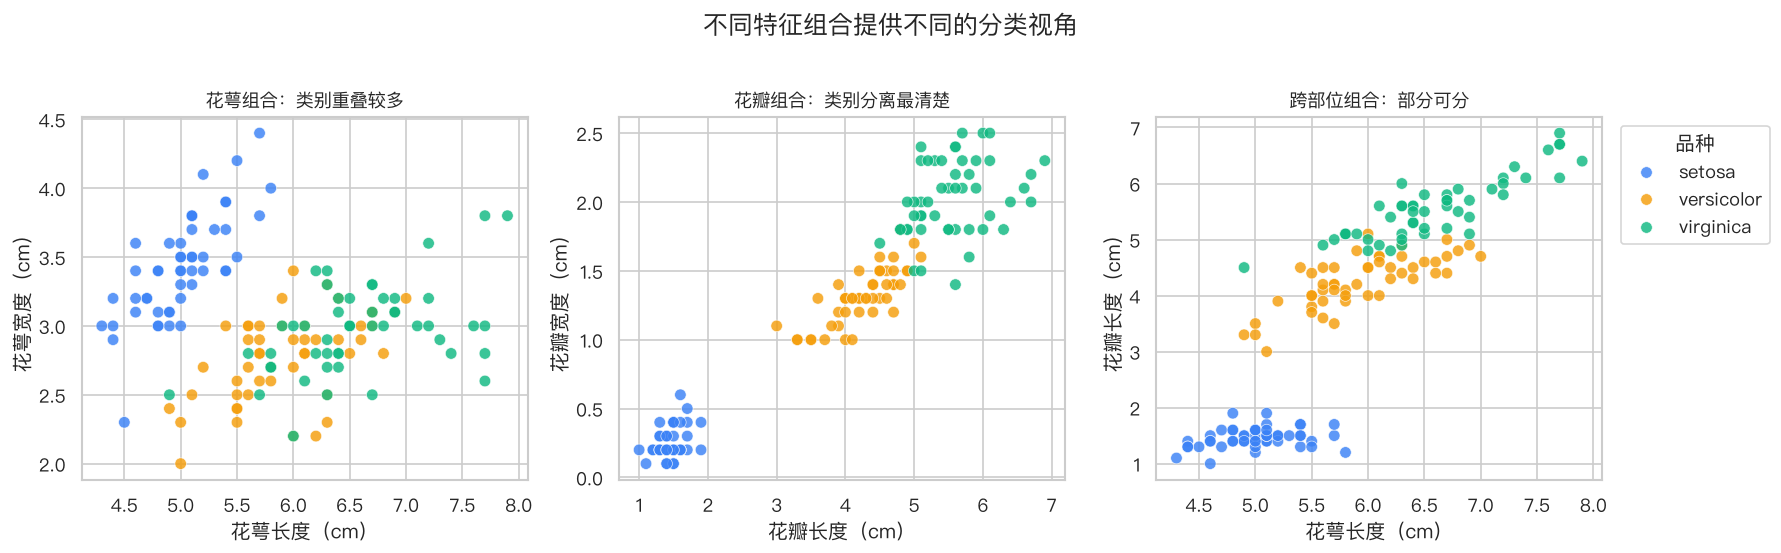

In [7]:
pairs = [
    ("花萼长度", "花萼宽度", "花萼组合：类别重叠较多"),
    ("花瓣长度", "花瓣宽度", "花瓣组合：类别分离最清楚"),
    ("花萼长度", "花瓣长度", "跨部位组合：部分可分"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x_col, y_col, title) in zip(axes, pairs):
    sns.scatterplot(data=df, x=x_col, y=y_col, hue="品种", palette=PALETTE,
                    s=48, alpha=0.82, edgecolor="white", linewidth=0.4, ax=ax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(f"{x_col}（cm）")
    ax.set_ylabel(f"{y_col}（cm）")
    if ax is not axes[2]:
        ax.get_legend().remove()
    else:
        ax.legend(title="品种", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("不同特征组合提供不同的分类视角", fontsize=15, y=1.02)
plt.tight_layout()
savefig("05_feature_pair_comparison.png")
plt.show()

**观察与结论**

- 花瓣长度与花瓣宽度相关系数约为 0.963，携带大量共同变化信息。
- 同时，它们构成的二维视角又最容易观察类别分离。
- 因此不能仅凭“高度相关”就删除其中一列。是否冗余取决于模型、解释目标和交叉验证结果；PCA 则会从另一角度把共同变化压缩成更少方向。

## 6. 特征构造：提出候选，不提前宣布有效

用花瓣长度与花瓣宽度的乘积构造一个面积代理。它不是植物学上的精确花瓣面积，只是演示如何把两个原始变量组合成一个更紧凑的数值表达。

,花瓣长度,花瓣宽度,花瓣面积代理,品种
0,1.4,0.2,0.28,setosa
1,1.4,0.2,0.28,setosa
2,1.3,0.2,0.26,setosa
3,1.5,0.2,0.30,setosa
4,1.4,0.2,0.28,setosa


已保存：实验/outputs/iris_data_analysis/06_engineered_feature.png


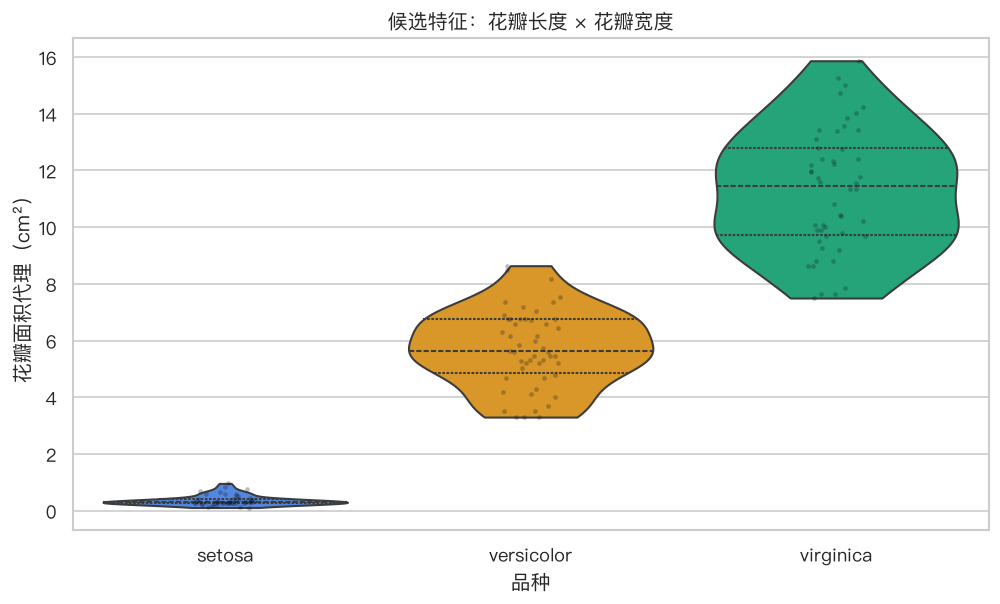

In [8]:
df_engineered = df.copy()
df_engineered["花瓣面积代理"] = df_engineered["花瓣长度"] * df_engineered["花瓣宽度"]
display(df_engineered[["花瓣长度", "花瓣宽度", "花瓣面积代理", "品种"]].head())

plt.figure(figsize=(8.5, 5.2))
sns.violinplot(data=df_engineered, x="品种", y="花瓣面积代理", hue="品种",
               palette=PALETTE, inner="quartile", cut=0, legend=False)
sns.stripplot(data=df_engineered, x="品种", y="花瓣面积代理",
              color="#111827", alpha=0.28, size=2.8)
plt.title("候选特征：花瓣长度 × 花瓣宽度")
plt.xlabel("品种")
plt.ylabel("花瓣面积代理（cm²）")
plt.tight_layout()
savefig("06_engineered_feature.png")
plt.show()

**观察与结论**

- 面积代理保留了明显的类别差异，提供了单轴观察视角。
- 它完全由两个原特征计算而来，没有增加新的测量信息，并且可能放大原特征的共线关系。
- 因此当前结论只能是“值得作为候选”。是否进入最终模型，要在训练集内部构造，并通过交叉验证比较加入前后的结果。

## 7. 实验结论与后续连接

| 结论 | 对后续章节的影响 |
|---|---|
| Iris 是 150×4 的数值分类数据，三类均衡 | 适合用分层划分和分类指标建立共同基线 |
| 花瓣特征的类别分离更清楚 | 适合用于逻辑回归、KNN、SVM 和决策树的二维边界展示 |
| 距离和梯度模型需要考虑尺度 | 后续在 Pipeline 中使用 StandardScaler，树模型保留原尺度作对照 |
| 花瓣长度与宽度高度相关 | 连接正则化、PCA 与特征选择 |
| 构造特征看似有用仍需验证 | 连接交叉验证与防止特征工程泄漏 |

本实验刻意没有训练模型。下一步是在保持测试集不可见的前提下，建立统一的数据划分、分类基线和评估流程。